## 📈 Ecommerce Customer Spending Prediction Using Linear Regression

Step 1: Import all dependencies

In [55]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

Step 2: Load the dataset

In [56]:
ecommerce_data = pd.read_csv('ecommerce-dataset.csv')

Step 3: Initial inspection of the dataset

In [57]:
df = ecommerce_data.copy()
df

,Email,Address,Avatar,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
0,mstephenson@fernandez.com,"835 Frank Tunnel\nWrightmouth, MI 82180-9605",Violet,34.497268,12.655651,39.577668,4.082621,587.951054
1,hduke@hotmail.com,"4547 Archer Common\nDiazchester, CA 06566-8576",DarkGreen,31.926272,11.109461,37.268959,2.664034,392.204933
2,pallen@yahoo.com,"24645 Valerie Unions Suite 582\nCobbborough, D...",Bisque,33.000915,11.330278,37.110597,4.104543,487.547505
3,riverarebecca@gmail.com,"1414 David Throughway\nPort Jason, OH 22070-1220",SaddleBrown,34.305557,13.717514,36.721283,3.120179,581.852344
4,mstephens@davidson-herman.com,"14023 Rodriguez Passage\nPort Jacobville, PR 3...",MediumAquaMarine,33.330673,12.795189,37.536653,4.446308,599.406092
...,...,...,...,...,...,...,...,...
495,lewisjessica@craig-evans.com,"4483 Jones Motorway Suite 872\nLake Jamiefurt,...",Tan,33.237660,13.566160,36.417985,3.746573,573.847438
496,katrina56@gmail.com,"172 Owen Divide Suite 497\nWest Richard, CA 19320",PaleVioletRed,34.702529,11.695736,37.190268,3.576526,529.049004
497,dale88@hotmail.com,"0787 Andrews Ranch Apt. 633\nSouth Chadburgh, ...",Cornsilk,32.646777,11.499409,38.332576,4.958264,551.620145
498,cwilson@hotmail.com,"680 Jennifer Lodge Apt. 808\nBrendachester, TX...",Teal,33.322501,12.391423,36.840086,2.336485,456.469510


In [58]:
df.describe()

,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
count,500.000000,500.000000,500.000000,500.000000,500.000000
mean,33.053194,12.052488,37.060445,3.533462,499.314038
std,0.992563,0.994216,1.010489,0.999278,79.314782
min,29.532429,8.508152,33.913847,0.269901,256.670582
25%,32.341822,11.388153,36.349257,2.930450,445.038277
50%,33.082008,11.983231,37.069367,3.533975,498.887875
75%,33.711985,12.753850,37.716432,4.126502,549.313828
max,36.139662,15.126994,40.005182,6.922689,765.518462


In [59]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Email                 500 non-null    object 
 1   Address               500 non-null    object 
 2   Avatar                500 non-null    object 
 3   Avg. Session Length   500 non-null    float64
 4   Time on App           500 non-null    float64
 5   Time on Website       500 non-null    float64
 6   Length of Membership  500 non-null    float64
 7   Yearly Amount Spent   500 non-null    float64
dtypes: float64(5), object(3)
memory usage: 31.4+ KB


In [60]:
df.columns = df.columns.str.lower().str.replace('.', '', regex=False).str.replace(' ', '_')

In [61]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   email                 500 non-null    object 
 1   address               500 non-null    object 
 2   avatar                500 non-null    object 
 3   avg_session_length    500 non-null    float64
 4   time_on_app           500 non-null    float64
 5   time_on_website       500 non-null    float64
 6   length_of_membership  500 non-null    float64
 7   yearly_amount_spent   500 non-null    float64
dtypes: float64(5), object(3)
memory usage: 31.4+ KB


Step 4: Exploratory Data Analysis

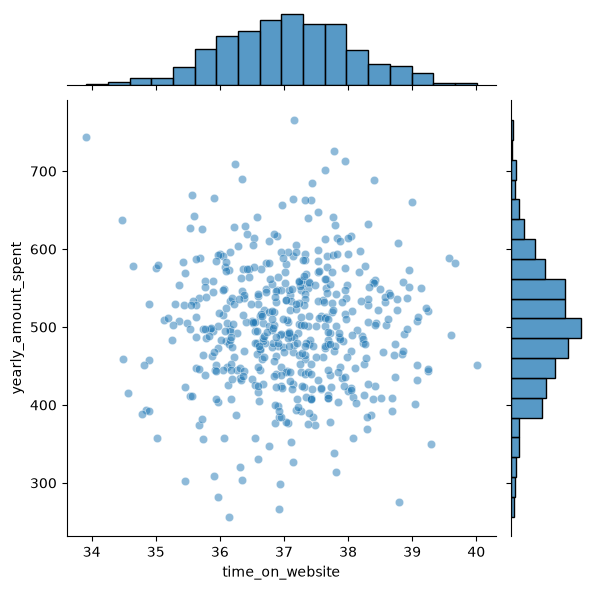

In [62]:
# Check for variable correlations (time_on_website vs yearly_amount_spent)

sns.jointplot(data=df, x='time_on_website', y='yearly_amount_spent', alpha=0.5)

plt.show()

In [63]:
# Check the correlation value (time_on_website vs yearly_amount_spent)

corr = df['time_on_website'].corr(df['yearly_amount_spent'])
print(f'Correlation: {corr:.3f}')

Correlation: -0.003


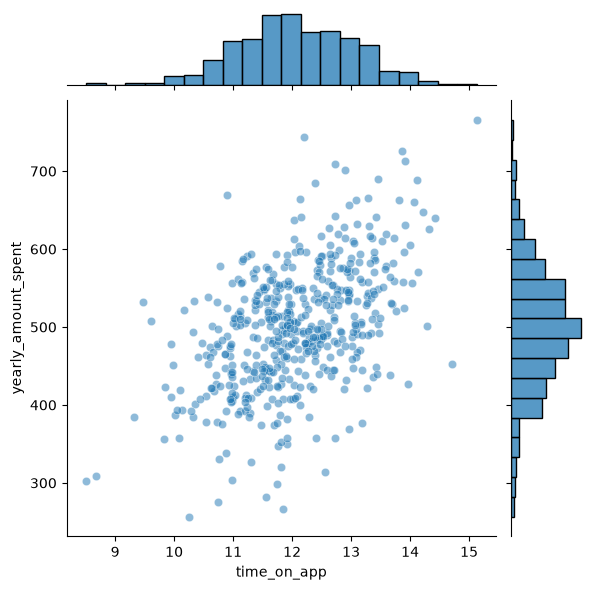

In [64]:
# Check for variable correlation ('time_on_app vs 'yealy_amount_spent')

sns.jointplot(data=df, x='time_on_app', y='yearly_amount_spent', alpha=0.5)

plt.show()

In [65]:
# Check the correlation value (time_on_app vs yearly_amount_spent)

corr = df['time_on_app'].corr(df['yearly_amount_spent'])
print(f'Correlation: {corr:.3f}')

Correlation: 0.499


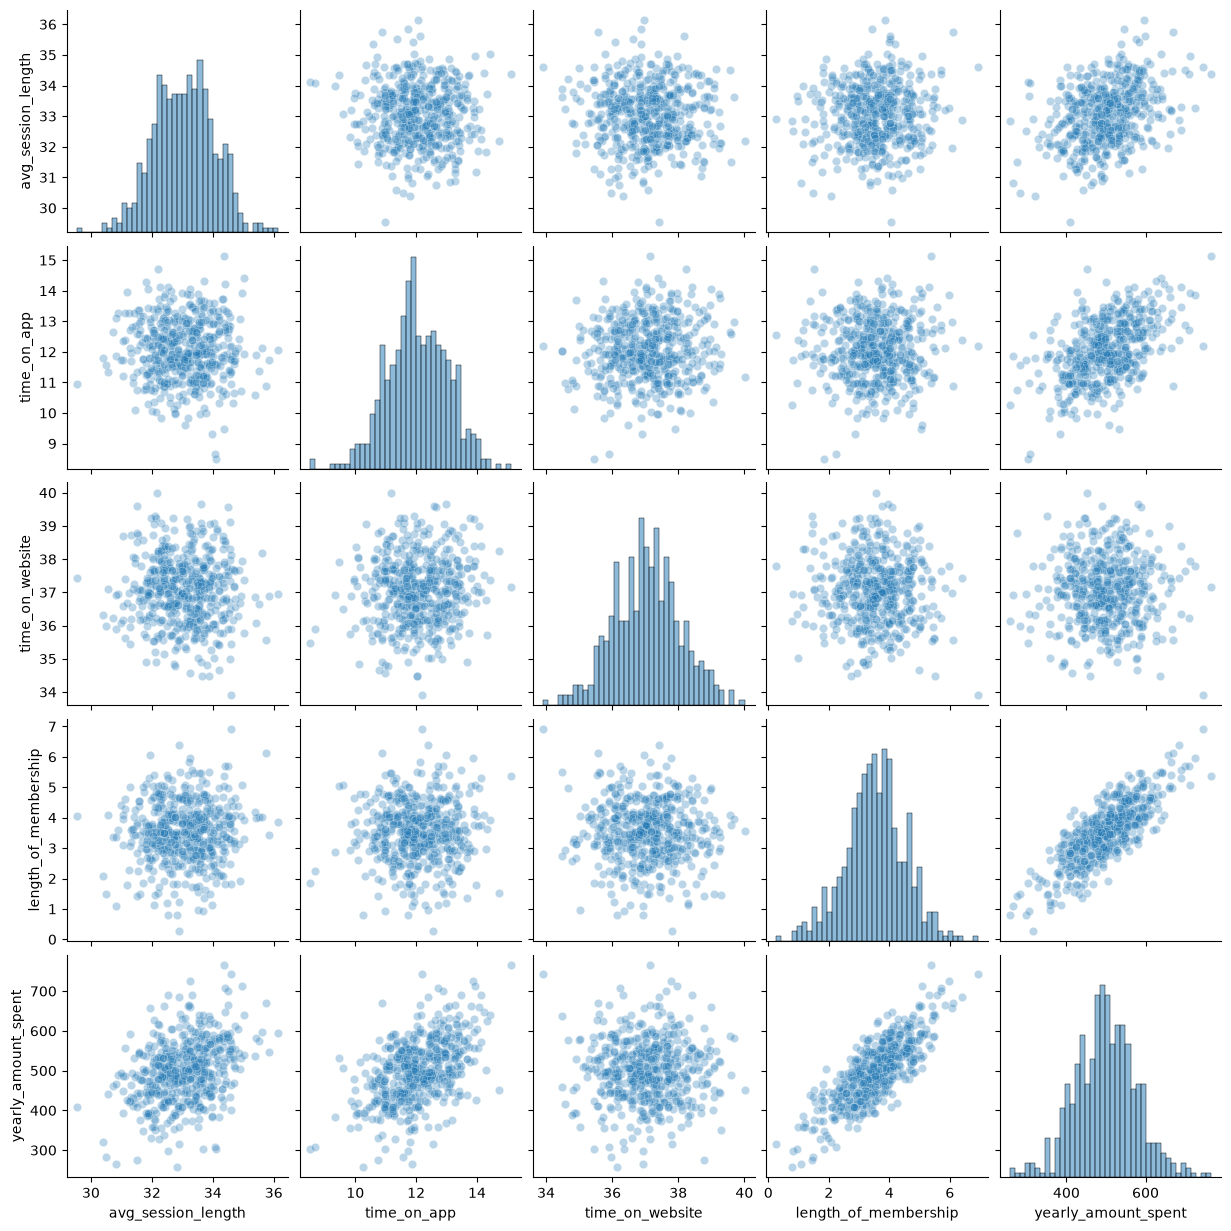

In [66]:
sns.pairplot(data=df, 
             kind='scatter', 
             plot_kws={'alpha':0.3}, 
             diag_kws={'alpha':0.5, 'bins':40})


Based on the pairplot, Length of Membership and Yearly Amount Spent appear to exhibit a strong positive linear relationship, making Length of Membership a promising predictor for a Linear Regression model.

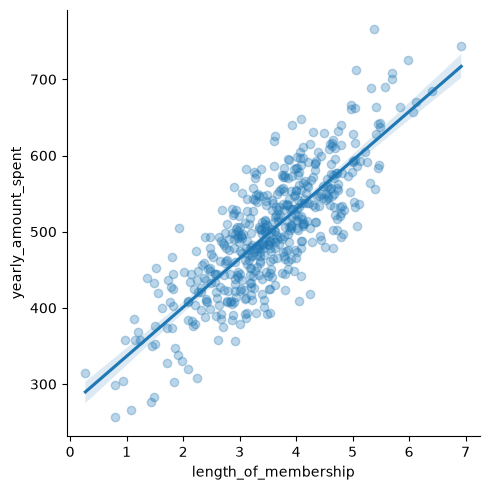

In [67]:
# Length of Membership vs Yearly Amount Spent

sns.lmplot(data=df,
           x='length_of_membership',
           y='yearly_amount_spent',
           scatter_kws={'alpha':0.3})

### Splitting the data

Before training the Linear Regression model, the dataset is divided into input features (X) and target variable (y).

The input features (X) represent the customers behaviour metrics, while the target variable (y) is the customer's yearly spending behaviour. The separation of the dataset allows the model to learn the relationship between the behaviour of the customers and their annual spending behaviour.

To evaluate the model's performance on unseen data, the dataset is further split into training and testing sets using Scikit-Learn test_train_split() function.

In [68]:
from sklearn.model_selection import train_test_split

In [69]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   email                 500 non-null    object 
 1   address               500 non-null    object 
 2   avatar                500 non-null    object 
 3   avg_session_length    500 non-null    float64
 4   time_on_app           500 non-null    float64
 5   time_on_website       500 non-null    float64
 6   length_of_membership  500 non-null    float64
 7   yearly_amount_spent   500 non-null    float64
dtypes: float64(5), object(3)
memory usage: 31.4+ KB


In [75]:
X = df[['avg_session_length', 'time_on_app', 'time_on_website', 'length_of_membership']]
y = df['yearly_amount_spent']

In [76]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.3, random_state=42)

### Training the Linear Regression Model

After splitting the data into training and testing sets, the next step is to train a Linear Regression model using Scikit-Learn.

The model learns the relationship between the customer features and yearly spending analyzing the patterns during training of the model. Once the model is trained, the model can be used to predict or estimate a customer's yearly spending based on the provided input metrics.

In [80]:
from sklearn.linear_model import LinearRegression

lm = LinearRegression()
lm.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[25.72,38.6 , 0.46,61.67]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['avg_session_length','time_on_app','time_on_website', 'length_of_membership']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-1051
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)


In [85]:
coef_df = pd.DataFrame({
    'Variable': X.columns,
    'Coefficient': lm.coef_
})

coef_df.sort_values('Coefficient', ascending=False)

,Variable,Coefficient
3,length_of_membership,61.674732
1,time_on_app,38.597135
0,avg_session_length,25.724256
2,time_on_website,0.459148


In [93]:
import statsmodels.api as sm

X_sm = sm.add_constant(X)

model = sm.OLS(y, X_sm)
results = model.fit()

print(results.summary())

                             OLS Regression Results                            
Dep. Variable:     yearly_amount_spent   R-squared:                       0.984
Model:                             OLS   Adj. R-squared:                  0.984
Method:                  Least Squares   F-statistic:                     7766.
Date:                 Mon, 19 Oct 2026   Prob (F-statistic):               0.00
Time:                         07:22:19   Log-Likelihood:                -1856.9
No. Observations:                  500   AIC:                             3724.
Df Residuals:                      495   BIC:                             3745.
Df Model:                            4                                         
Covariance Type:             nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                -

### Model Predictions

After training the Linear Regression model, the predictions are then generated using the test dataset.

Comparing the predicted values with the actual yearly spending values provides an initial assessment of the model's performance. If the generated prediction values closely match the actual values, this suggests that the model has successfully learned the underlying relationships in the dataset.

In [94]:
predictions = lm.predict(X_test)

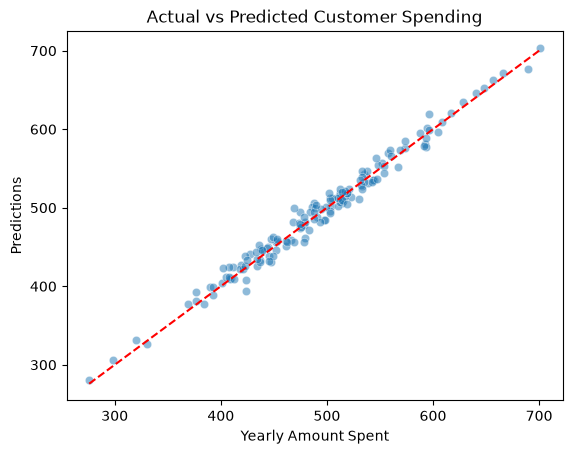

In [114]:
sns.scatterplot(x=y_test, y=predictions, alpha=0.5)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red',
    linestyle='--',
    linewidth=1.5
)

plt.xlabel('Yearly Amount Spent')
plt.ylabel('Predictions')
plt.title('Actual vs Predicted Customer Spending')

plt.show()

### Model Evaluation

After generating predictions on the test dataset, several regression metrics were used to evaluate the model's performance.

**Mean Squared Error (MSE):** Measures the average squared prediction error. Larger errors receive a greater penalty due to the squaring operation.

**Mean Absolute Error (MAE):** Measures the average absolute difference between the actual and predicted values.

**Root Mean Squared Error (RMSE):** Represents the typical prediction error in the same units as the target variable, making it easier to interpret.

In [128]:
from sklearn.metrics import mean_squared_error, mean_absolute_error
import math

In [127]:
print('Mean Squared Error:',mean_squared_error(y_test, predictions))
print('Mean Absolute Error:', mean_absolute_error(y_test, predictions))
print('Root Mean Squared:', math.sqrt(mean_squared_error(y_test, predictions)))

Mean Squared Error: 103.91554136503333
Mean Absolute Error: 8.426091641432116
Root Mean Squared: 10.193897260863155
